In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
    AdaBoostRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, VotingRegressor, StackingRegressor
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [5]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\my_projects\Project Ames Housing Dataset\Ames Housing Dataset.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [25]:
print("Shape:", df.shape)
df.info()

Shape: (1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  O

In [26]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [27]:
df.duplicated().sum()

np.int64(0)

In [8]:
data = df.copy()

data = data.drop_duplicates()
data = data.dropna(subset=["SalePrice"])
data = data.drop(columns=["Id"], errors="ignore")

absence_categories = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "MiscFeature"
]

for col in absence_categories:
    if col in data.columns:
        data[col] = data[col].fillna("None")

zero_if_absent = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "GarageCars",
    "GarageArea", "PoolArea", "MiscVal"
]

for col in zero_if_absent:
    if col in data.columns:
        data[col] = data[col].fillna(0)

data["LotFrontage"] = data["LotFrontage"].fillna(data["LotFrontage"].median())

numeric_cols = data.select_dtypes(include=np.number).columns
categorical_cols = data.select_dtypes(exclude=np.number).columns

for col in categorical_cols:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode().iloc[0])

for col in numeric_cols:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].median())

data["HouseAgeAtSale"] = data["YrSold"] - data["YearBuilt"]
data["YearsSinceRemodel"] = data["YrSold"] - data["YearRemodAdd"]
data["TotalPorchSF"] = (
    data["WoodDeckSF"] + data["OpenPorchSF"] +
    data["EnclosedPorch"] + data["3SsnPorch"] + data["ScreenPorch"]
)
data["TotalBathrooms"] = (
    data["FullBath"] + 0.5 * data["HalfBath"] +
    data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"]
)

data = data.replace([np.inf, -np.inf], np.nan)
print("Cleaned shape:", data.shape)
print("Remaining missing values:", data.isna().sum().sum())
display(data.head())

Cleaned shape: (1460, 84)
Remaining missing values: 0


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,HouseAgeAtSale,YearsSinceRemodel,TotalPorchSF,TotalBathrooms
0,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,None,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,None,None,None,0,2,2008,WD,Normal,208500,5,5,61,3.5
1,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,None,None,None,0,5,2007,WD,Normal,181500,31,31,298,2.5
2,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,None,None,None,0,9,2008,WD,Normal,223500,7,6,42,3.5
3,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,None,None,None,0,2,2006,WD,Abnorml,140000,91,36,307,2.0
4,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,None,None,None,0,12,2008,WD,Normal,250000,8,8,276,3.5


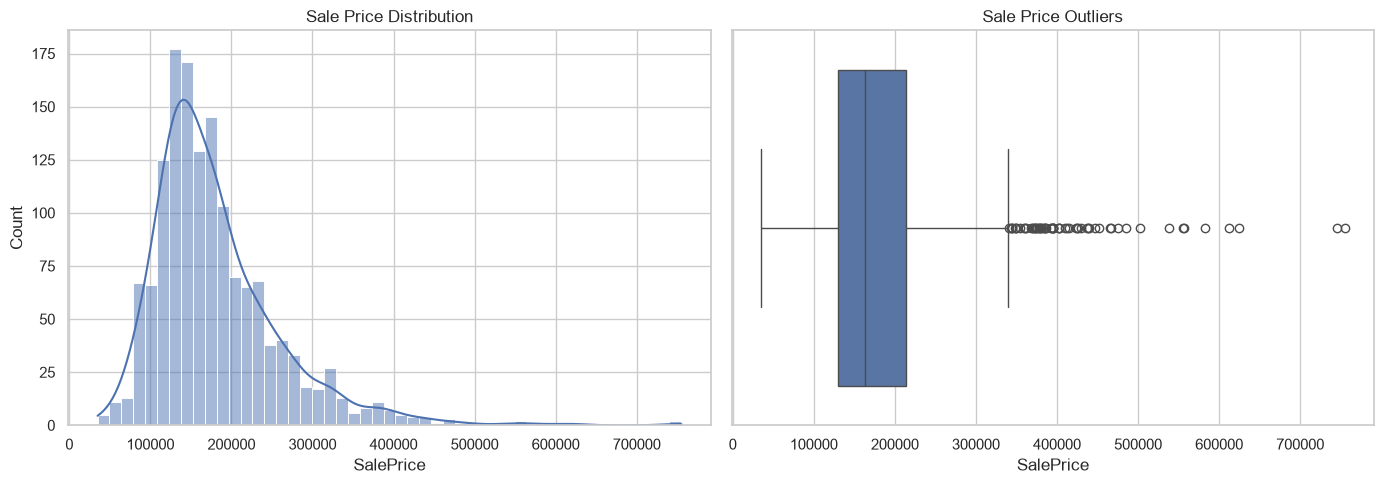

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Sale Price Distribution")
sns.boxplot(x=data["SalePrice"], ax=axes[1])
axes[1].set_title("Sale Price Outliers")
plt.tight_layout()
plt.show()

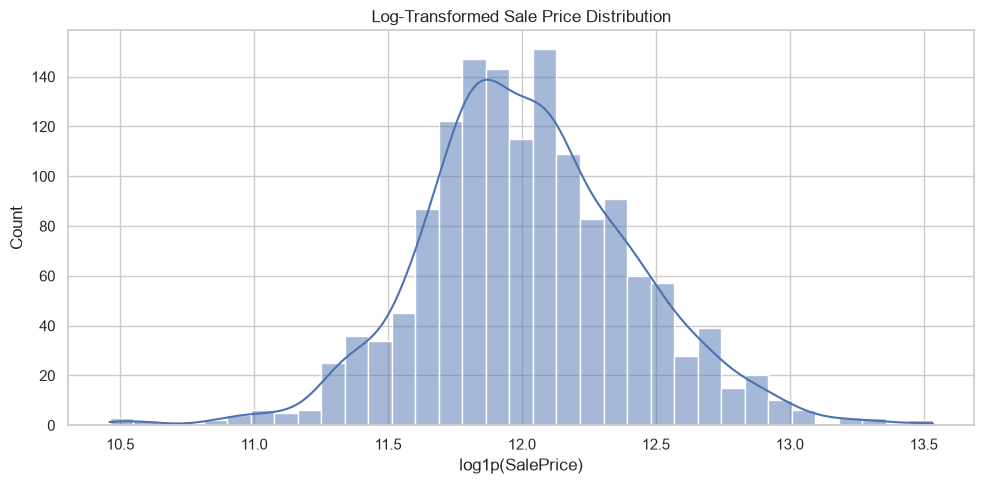

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(data["SalePrice"]), kde=True)
plt.title("Log-Transformed Sale Price Distribution")
plt.xlabel("log1p(SalePrice)")
plt.tight_layout()
plt.show()

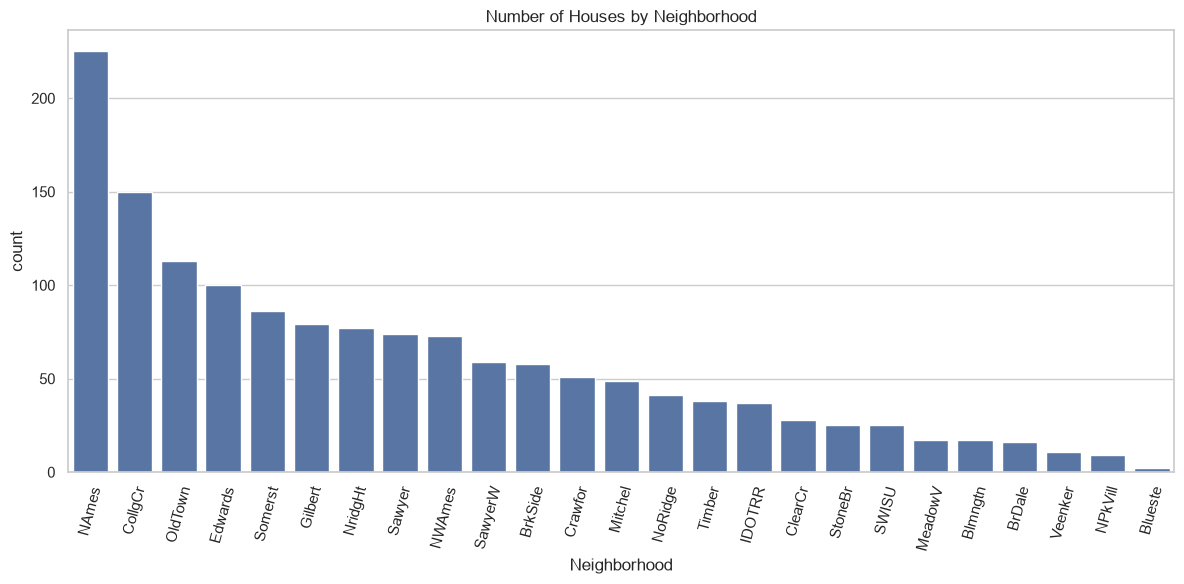

In [11]:
plt.figure(figsize=(12, 6))
sns.countplot(data=data, x="Neighborhood", order=data["Neighborhood"].value_counts().index)
plt.title("Number of Houses by Neighborhood")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

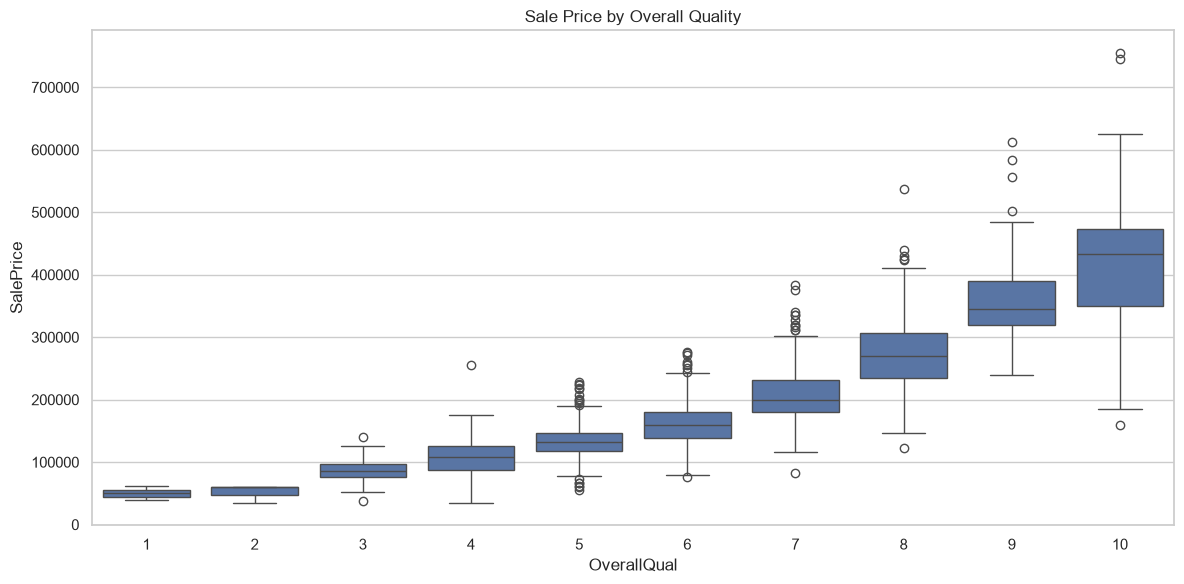

In [12]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="OverallQual", y="SalePrice")
plt.title("Sale Price by Overall Quality")
plt.tight_layout()
plt.show()

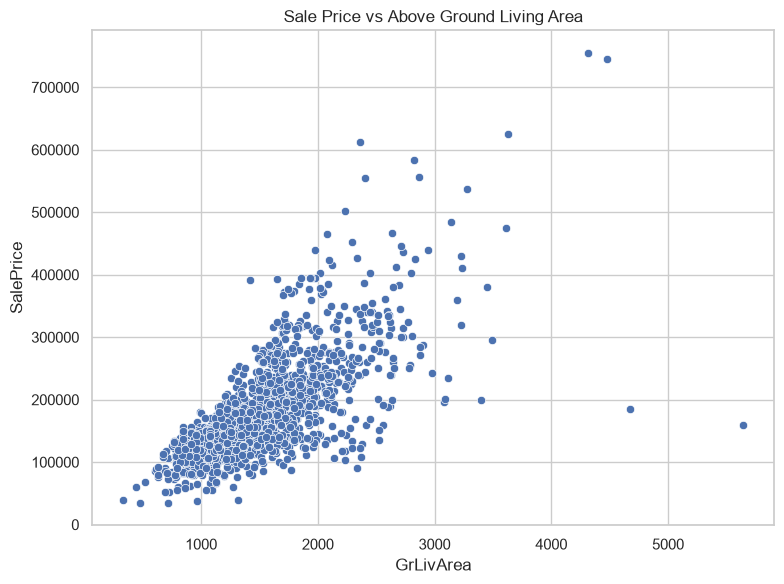

In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="GrLivArea", y="SalePrice")
plt.title("Sale Price vs Above Ground Living Area")
plt.tight_layout()
plt.show()

SalePrice         1.000000
OverallQual       0.790982
GrLivArea         0.708624
GarageCars        0.640409
TotalBathrooms    0.631731
GarageArea        0.623431
TotalBsmtSF       0.613581
1stFlrSF          0.605852
FullBath          0.560664
TotRmsAbvGrd      0.533723
YearBuilt         0.522897
YearRemodAdd      0.507101
MasVnrArea        0.472614
Fireplaces        0.466929
GarageYrBlt       0.466754
Name: SalePrice, dtype: float64

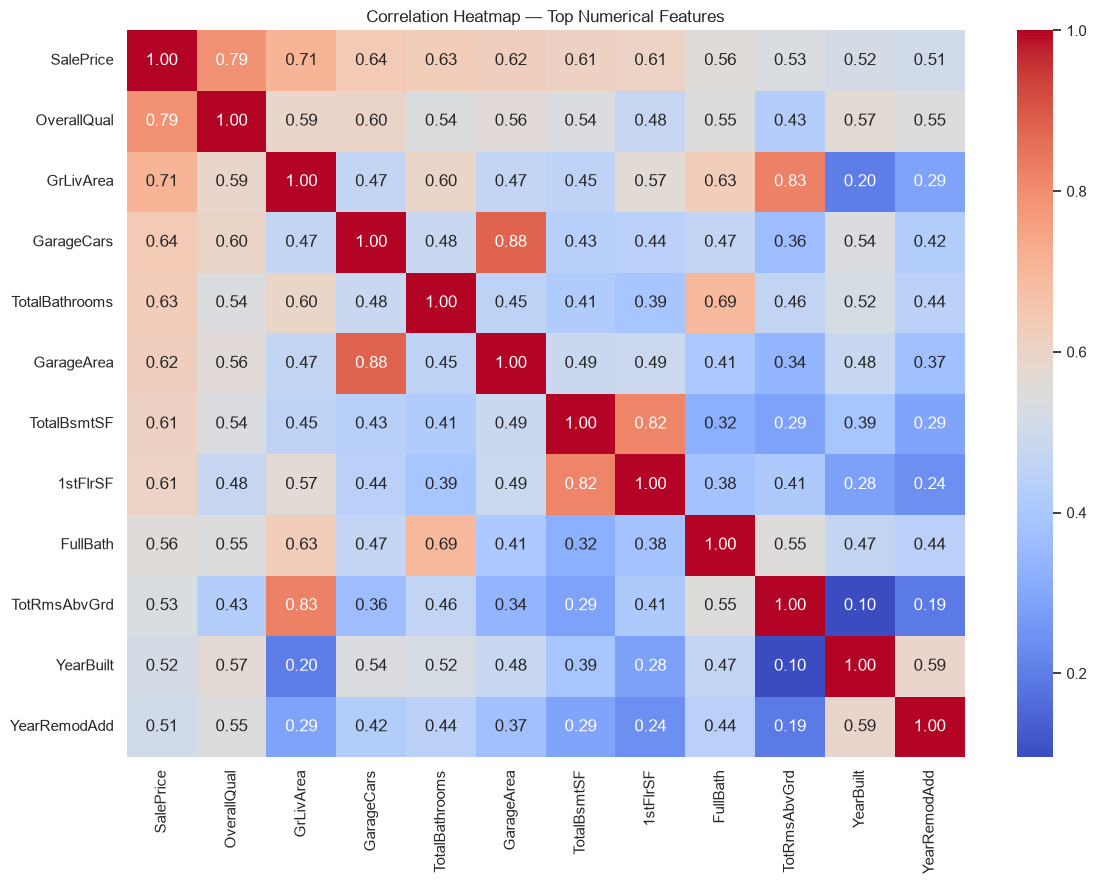

In [14]:
top_corr = data.select_dtypes(include=np.number).corr()["SalePrice"].sort_values(ascending=False)
display(top_corr.head(15))

plt.figure(figsize=(12, 9))
selected = top_corr.head(12).index
sns.heatmap(data[selected].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap — Top Numerical Features")
plt.tight_layout()
plt.show()

In [15]:
X = data.drop(columns=["SalePrice"])
y = data["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X_train: (1168, 83) y_train: (1168,)
X_test: (292, 83) y_test: (292,)


In [16]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed train shape: (1168, 304)
Processed test shape: (292, 304)


In [17]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(alpha=0.001, max_iter=20000),
    "Ridge": Ridge(alpha=10.0),
    "KNN": KNeighborsRegressor(n_neighbors=5, p=1),
    "SVM": SVR(kernel="rbf", C=100, epsilon=0.1),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=18, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesRegressor(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE),
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE),
        n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "AdaBoost": AdaBoostRegressor(n_estimators=75, learning_rate=0.05, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=RANDOM_STATE)
}

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        subsample=0.9, colsample_bytree=0.9,
        objective="reg:squarederror", n_jobs=-1,
        random_state=RANDOM_STATE, verbosity=0
    )
except ImportError:
    print("XGBoost is not installed; skipping it.")

try:
    from catboost import CatBoostRegressor
    models["CatBoost"] = CatBoostRegressor(
        iterations=200, learning_rate=0.05, depth=6,
        verbose=0, random_seed=RANDOM_STATE, allow_writing_files=False
    )
except ImportError:
    print("CatBoost is not installed; skipping it.")

try:
    from lightgbm import LGBMRegressor
    models["LightGBM"] = LGBMRegressor(
        n_estimators=200, learning_rate=0.05,
        verbosity=-1, n_jobs=-1, random_state=RANDOM_STATE
    )
except ImportError:
    print("LightGBM is not installed; skipping it.")

print("Models to train:", list(models.keys()))

Models to train: ['Linear Regression', 'Lasso', 'Ridge', 'KNN', 'SVM', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Bagging', 'AdaBoost', 'Gradient Boosting', 'Hist Gradient Boosting', 'XGBoost', 'CatBoost', 'LightGBM']


Training: Linear Regression


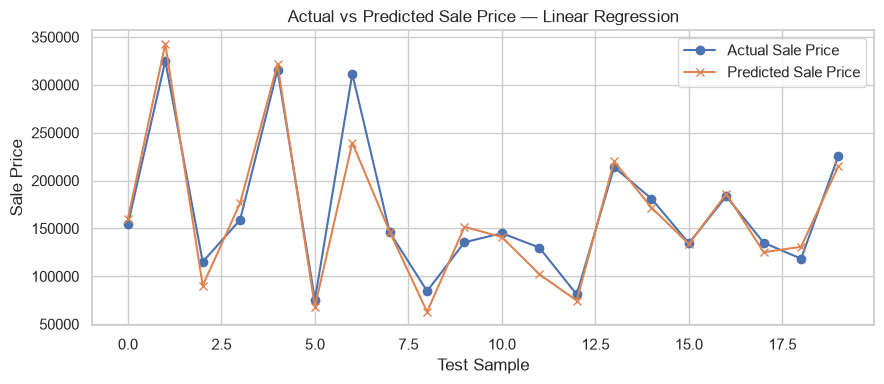

Training: Lasso


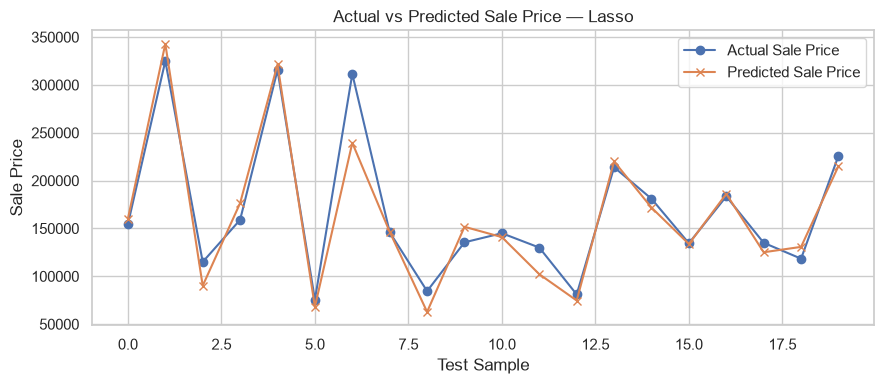

Training: Ridge


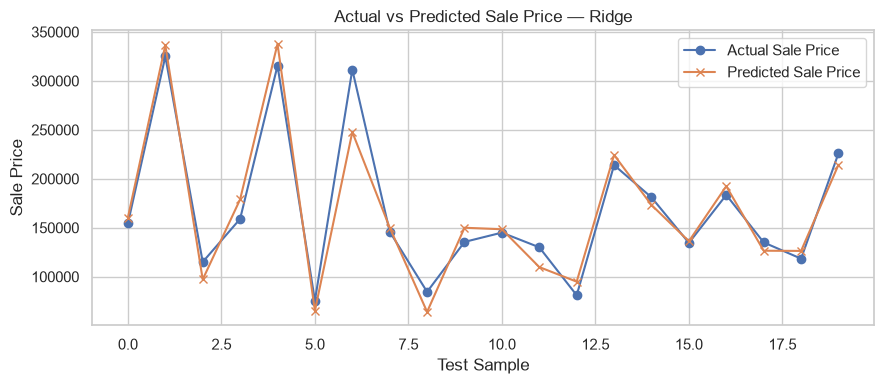

Training: KNN


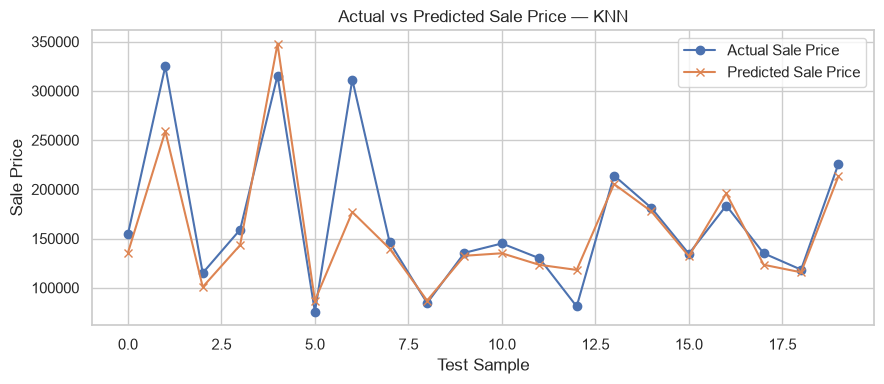

Training: SVM


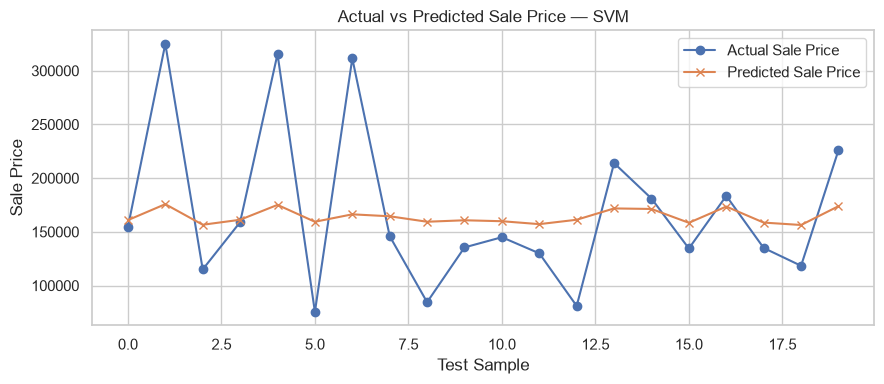

Training: Decision Tree


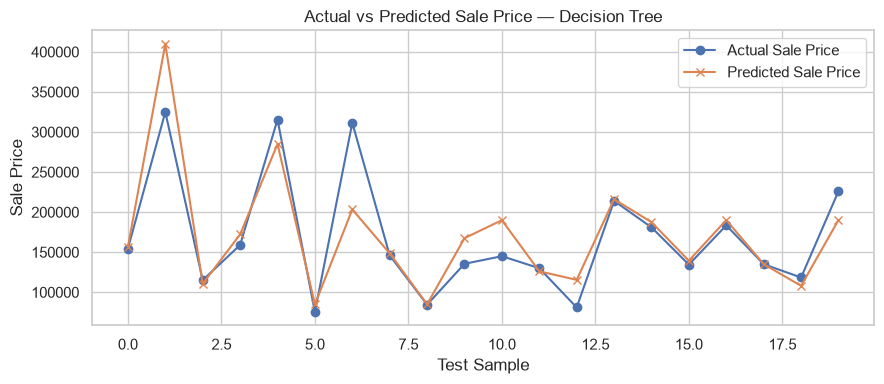

Training: Random Forest


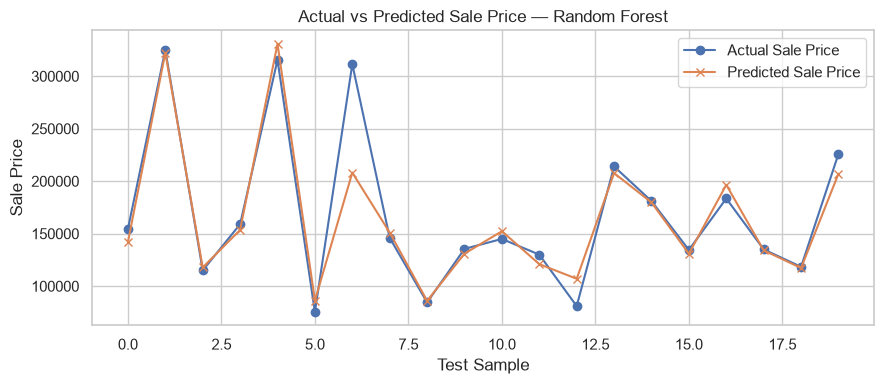

Training: Extra Trees


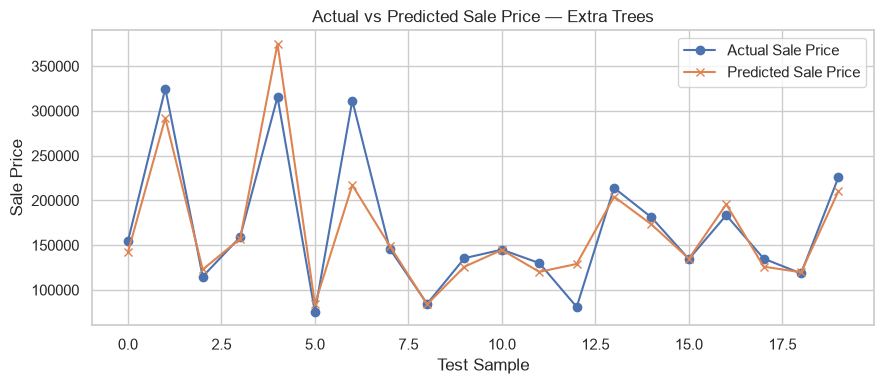

Training: Bagging


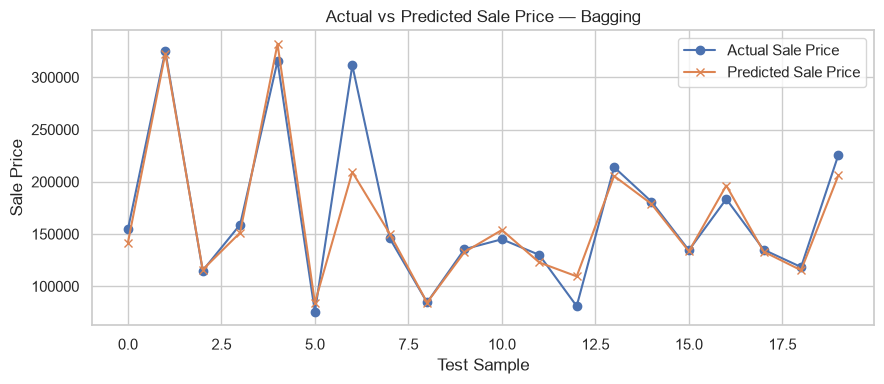

Training: AdaBoost


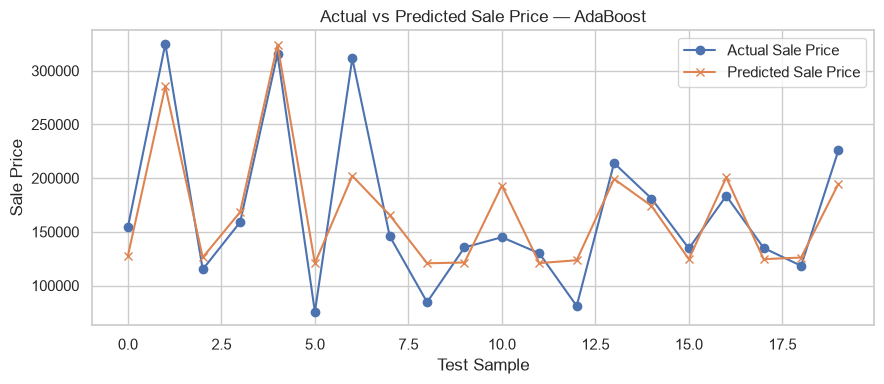

Training: Gradient Boosting


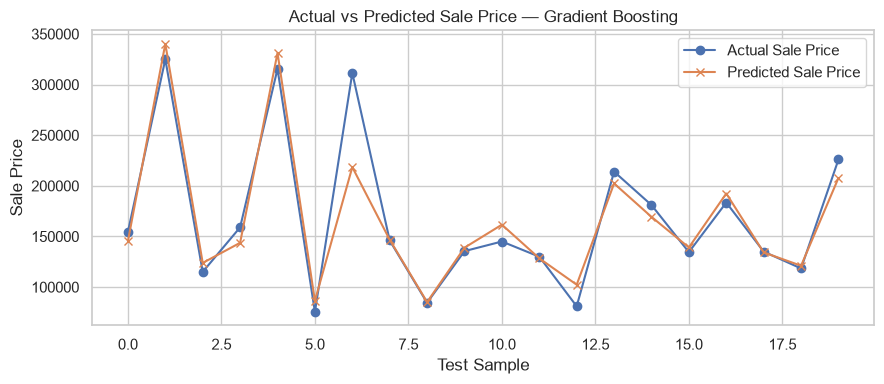

Training: Hist Gradient Boosting


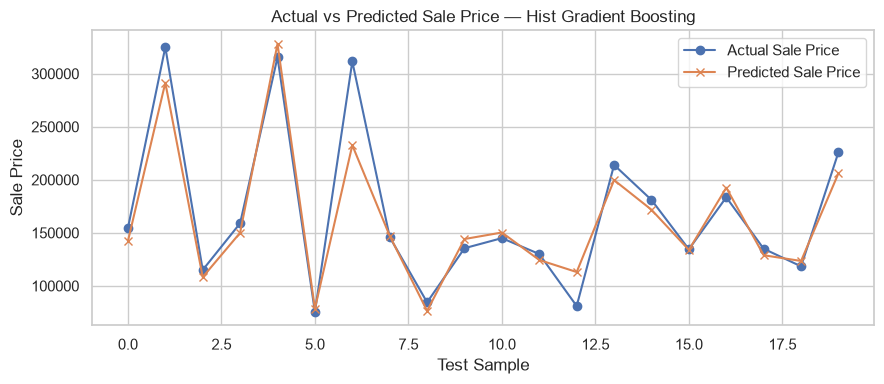

Training: XGBoost


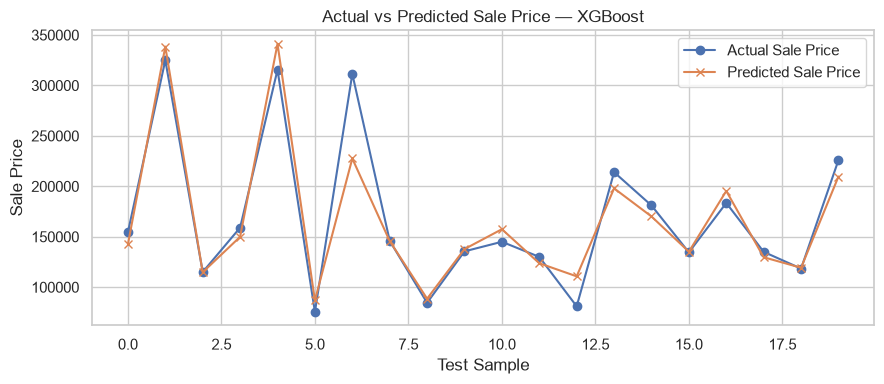

Training: CatBoost


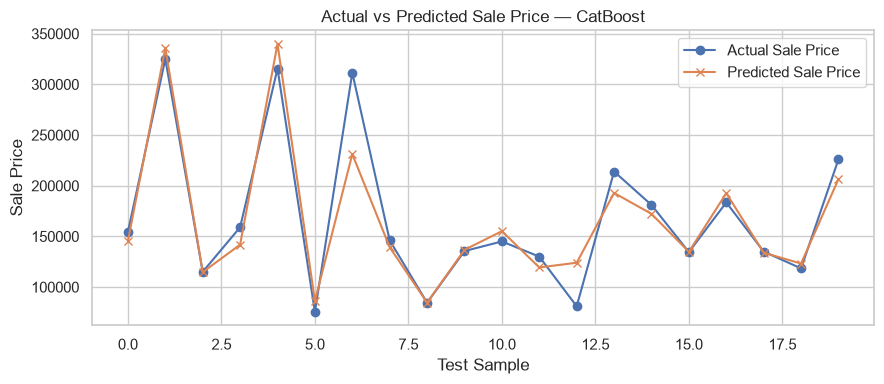

Training: LightGBM


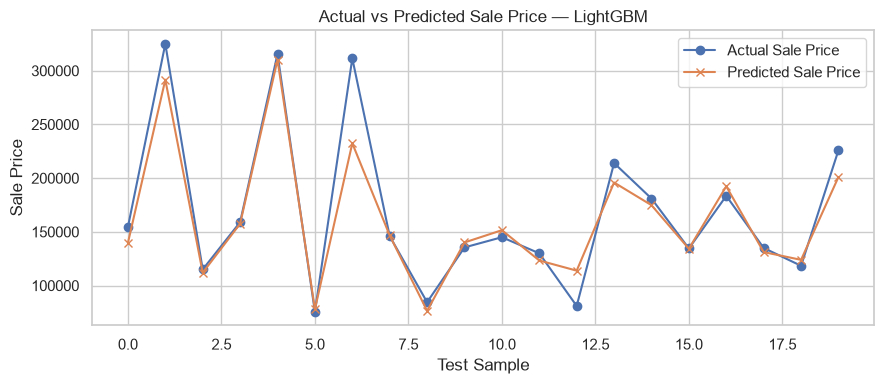

In [18]:
def regression_metrics(model, X_data, y_actual):
    predictions = model.predict(X_data)
    mae = mean_absolute_error(y_actual, predictions)
    mse = mean_squared_error(y_actual, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, predictions)
    return mae, mse, rmse, r2

errors = {}
trained_models = {}

for model_name, model in models.items():
    print("Training:", model_name)
    model.fit(X_train_processed, y_train)
    trained_models[model_name] = model

    train_metrics = regression_metrics(model, X_train_processed, y_train)
    test_metrics = regression_metrics(model, X_test_processed, y_test)

    errors[model_name] = {
        "MAE Train": train_metrics[0], "MAE Test": test_metrics[0],
        "MSE Train": train_metrics[1], "MSE Test": test_metrics[1],
        "RMSE Train": train_metrics[2], "RMSE Test": test_metrics[2],
        "R2 Train": train_metrics[3], "R2 Test": test_metrics[3]
    }

    n = min(20, len(y_test))
    predictions = model.predict(X_test_processed[:n])
    plt.figure(figsize=(9, 4))
    plt.plot(range(n), y_test.iloc[:n].values, marker="o", label="Actual Sale Price")
    plt.plot(range(n), predictions, marker="x", label="Predicted Sale Price")
    plt.title("Actual vs Predicted Sale Price — " + model_name)
    plt.xlabel("Test Sample")
    plt.ylabel("Sale Price")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Voting Regression

In [19]:
voting_estimators = []
for key, short_name in [
    ("Linear Regression", "lr"),
    ("Random Forest", "rf"),
    ("Gradient Boosting", "gb")
]:
    if key in trained_models:
        voting_estimators.append((short_name, trained_models[key]))

if len(voting_estimators) >= 2:
    voting_model = VotingRegressor(estimators=voting_estimators, n_jobs=-1)
    voting_model.fit(X_train_processed, y_train)

    train_metrics = regression_metrics(voting_model, X_train_processed, y_train)
    test_metrics = regression_metrics(voting_model, X_test_processed, y_test)

    errors["Voting"] = {
        "MAE Train": train_metrics[0], "MAE Test": test_metrics[0],
        "MSE Train": train_metrics[1], "MSE Test": test_metrics[1],
        "RMSE Train": train_metrics[2], "RMSE Test": test_metrics[2],
        "R2 Train": train_metrics[3], "R2 Test": test_metrics[3]
    }

## Stacking Regression

In [20]:
stacking_estimators = []
for key, short_name in [
    ("Random Forest", "rf"),
    ("Gradient Boosting", "gb"),
    ("Extra Trees", "et")
]:
    if key in trained_models:
        stacking_estimators.append((short_name, trained_models[key]))

if len(stacking_estimators) >= 2:
    stacking_model = StackingRegressor(
        estimators=stacking_estimators,
        final_estimator=Ridge(alpha=10.0),
        cv=5,
        n_jobs=-1
    )
    stacking_model.fit(X_train_processed, y_train)

    train_metrics = regression_metrics(stacking_model, X_train_processed, y_train)
    test_metrics = regression_metrics(stacking_model, X_test_processed, y_test)

    errors["Stacking"] = {
        "MAE Train": train_metrics[0], "MAE Test": test_metrics[0],
        "MSE Train": train_metrics[1], "MSE Test": test_metrics[1],
        "RMSE Train": train_metrics[2], "RMSE Test": test_metrics[2],
        "R2 Train": train_metrics[3], "R2 Test": test_metrics[3]
    }

## Model Comparison

In [21]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
display(errors_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,7556.525879,15875.654297,1.064110e+08,6.281974e+08,10315.572694,25063.865943,0.982159,0.918100
Stacking,7649.495298,16363.043668,1.131261e+08,6.795824e+08,10636.073857,26068.801363,0.981034,0.911401
Gradient Boosting,10567.491091,17003.206285,2.116468e+08,7.162813e+08,14548.084635,26763.432391,0.964516,0.906617
CatBoost,10916.172060,16559.840265,2.304221e+08,7.187447e+08,15179.660672,26809.414650,0.961368,0.906295
Random Forest,6514.489307,17359.078362,1.246260e+08,8.199215e+08,11163.599694,28634.271005,0.979106,0.893105
Extra Trees,0.000000,18028.375251,0.000000e+00,8.264448e+08,0.000000,28747.953054,1.000000,0.892254
Hist Gradient Boosting,4333.417937,16900.748532,8.973481e+07,8.408723e+08,9472.846158,28997.797602,0.984955,0.890373
LightGBM,5082.067311,16794.029018,1.183041e+08,8.580227e+08,10876.770766,29292.025092,0.980165,0.888137
Bagging,7289.147606,18122.434312,1.439868e+08,8.993957e+08,11999.448597,29989.926899,0.975860,0.882743
Ridge,14912.080948,19170.369247,5.933613e+08,9.316950e+08,24359.009374,30523.679439,0.900519,0.878533


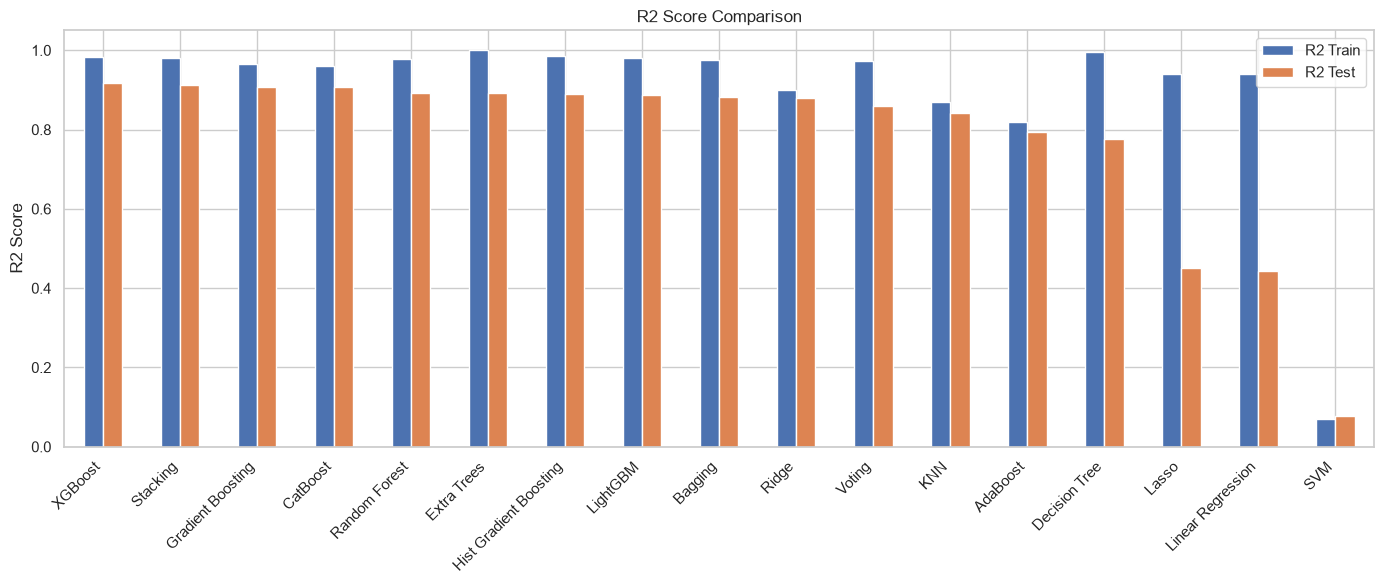

In [22]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(14, 6))
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

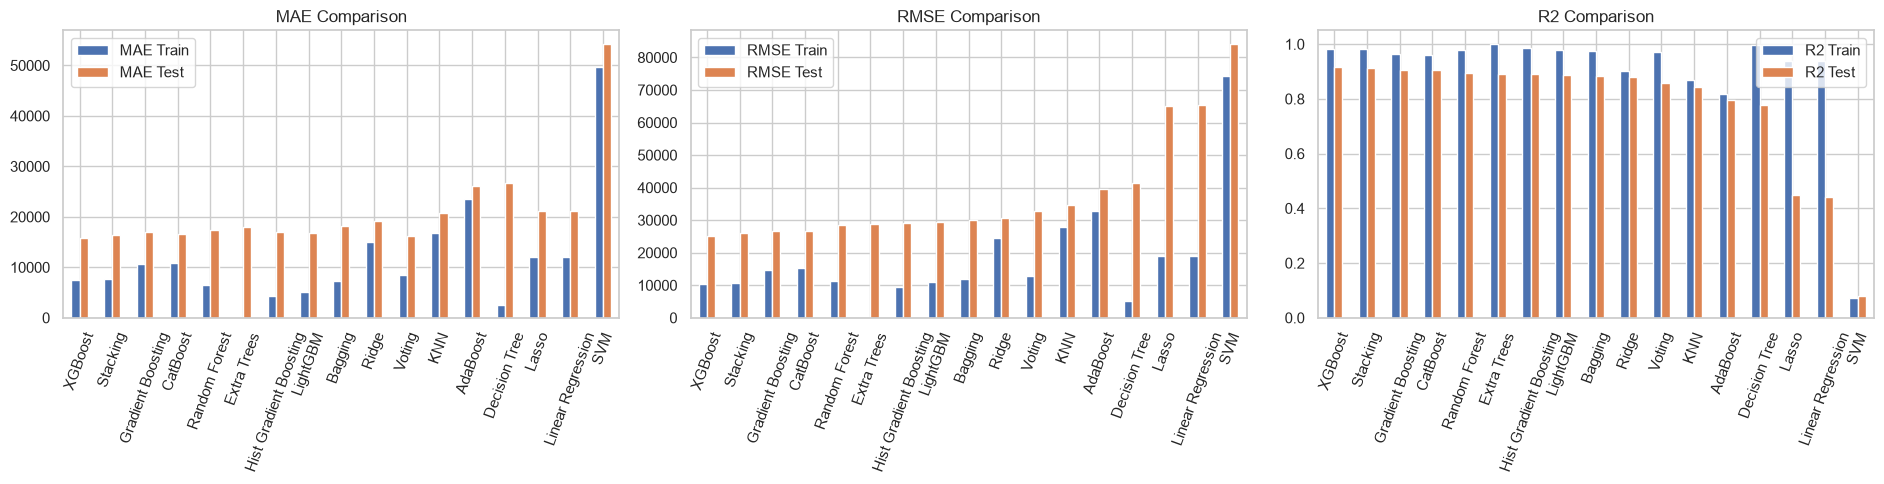

In [23]:
metrics_to_plot = [
    ["MAE Train", "MAE Test"],
    ["RMSE Train", "RMSE Test"],
    ["R2 Train", "R2 Test"]
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, metric in zip(axes, metrics_to_plot):
    errors_df[metric].plot.bar(ax=ax)
    ax.set_title(metric[0].split()[0] + " Comparison")
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

In [24]:
best_model_name = errors_df["R2 Test"].idxmax()
print("Best model:", best_model_name)
display(errors_df.loc[[best_model_name]])

if best_model_name in trained_models:
    best_model = trained_models[best_model_name]
    predictions = best_model.predict(X_test_processed[:10])
    comparison = pd.DataFrame({
        "Actual SalePrice": y_test.iloc[:10].values,
        "Predicted SalePrice": predictions
    })
    comparison["Absolute Error"] = (
        comparison["Actual SalePrice"] - comparison["Predicted SalePrice"]
    ).abs()
    display(comparison)

Best model: XGBoost


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,7556.525879,15875.654297,106411040.0,628197376.0,10315.572694,25063.865943,0.982159,0.9181


,Actual SalePrice,Predicted SalePrice,Absolute Error
0,154500,142517.468750,11982.531250
1,325000,338519.406250,13519.406250
2,115000,114770.351562,229.648438
3,159000,149935.734375,9064.265625
4,315500,341213.968750,25713.968750
5,75500,86825.898438,11325.898438
6,311500,227579.765625,83920.234375
7,146000,145698.750000,301.250000
8,84500,88556.570312,4056.570312
9,135500,137748.203125,2248.203125
